# Phase 4: evaluate (faster cut)
Answers the plan's five questions from the frozen and graded Phase 3 outputs; nothing is re-estimated. Questions 1, 2 and 5 in full (paired comparisons with bootstrap intervals, the maturity chart, the loss ratio test); questions 3 and 4 as short tables. Then the error drivers: ceded swing as a confounder, and the direction of survivorship bias.

Inputs: `results/graded_lines.csv` and `results/graded_ay.csv` from `notebooks/05_phase3_grade.ipynb` (rebuilt by it if missing). Head-to-head comparisons use the D4 common sample (PPA 109, WC 59 lines). "Headline" = CL and BF on volume-weighted all-years factors (D3).

Signs: error = estimate − actual. Positive = over-reserved.

In [1]:
# Setup
import sys; sys.path.insert(0, "..")
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)
R = Path("../results"); FIG = Path("../docs/figures"); FIG.mkdir(parents=True, exist_ok=True)
assert (R / "graded_lines.csv").exists(), "run notebooks/05_phase3_grade.ipynb first"
lines = pd.read_csv(R / "graded_lines.csv")
ay = pd.read_csv(R / "graded_ay.csv")
est = pd.read_csv(R / "estimates.csv", usecols=["lob", "GRCODE", "basis", "AccidentYear", "ep", "latest", "method", "average", "elr"])

HEAD = "volume_all"
def combo(df):
    return np.select([df.method == "cl", df.method == "ec"],
                     ["CL", "EC " + df.elr.fillna("")], "BF " + df.elr.fillna(""))
for d in (lines, ay):
    d["combo"] = combo(d)
    d["headline"] = (d.method == "ec") | (d.average == HEAD)
common = lines.loc[lines.in_common, ["lob", "GRCODE"]].drop_duplicates()
ay = ay.merge(common.assign(in_common=True), on=["lob", "GRCODE"], how="left").fillna({"in_common": False})
ORDER = ["CL", "BF company", "BF industry", "EC company", "EC industry"]
pct = lambda x: f"{x:+.1%}"
rng = np.random.default_rng(20261108)  # bootstrap seed, fixed before any interval was computed
print("common-sample lines:", common.groupby("lob").size().to_dict())

common-sample lines: {'PPA': 109, 'WC': 59}


## Question 1: most accurate method on total reserves, by line
Paired comparison: for each line, |error| of chain ladder minus |error| of the other method, both as % of reserve on the line total (AYs 1999–2007). Negative = chain ladder closer on that line. Pairing removes company-to-company noise: a hard-to-reserve line is hard for both methods, and the difference cancels it. The interval is a 95% bootstrap interval for the median difference (2,000 resamples of lines). Lines whose actual unpaid total is ≤ 0 have no % of reserve and are left out of these pairs.

In [2]:
# Q1: paired |error| differences vs chain ladder, headline combinations, common sample
def boot_median(x, reps=2000):
    x = np.asarray(x); idx = rng.integers(0, len(x), (reps, len(x)))
    return np.percentile(np.median(x[idx], axis=1), [2.5, 97.5])

h = lines[lines.in_common & lines.headline]
w = h.pivot_table(index=["lob", "basis", "GRCODE"], columns="combo", values="pct_reserve")
rows = []
for (lob, basis), g in w.groupby(level=[0, 1]):
    for other in ORDER[1:]:
        pair = g[["CL", other]].dropna()
        d = pair.CL.abs() - pair[other].abs()
        lo, hi = boot_median(d)
        rows.append({"lob": lob, "basis": basis, "vs": other, "n": len(d),
                     "med_abs_CL": pair.CL.abs().median(), "med_abs_other": pair[other].abs().median(),
                     "med_diff": d.median(), "ci_lo": lo, "ci_hi": hi,
                     "CL_closer": (d < 0).mean()})
q1 = pd.DataFrame(rows)
q1.to_csv("../docs/phase4_q1_paired.csv", index=False, float_format="%.6f")
fmt = {c: "{:.1%}".format for c in ["med_abs_CL", "med_abs_other", "CL_closer"]}
fmt |= {c: "{:+.1%}".format for c in ["med_diff", "ci_lo", "ci_hi"]}
print(q1.to_string(index=False, formatters=fmt))

lob    basis          vs   n med_abs_CL med_abs_other med_diff   ci_lo  ci_hi CL_closer
PPA     paid  BF company 101      18.8%         22.8%    -1.0%   -5.7%  +2.9%     52.5%
PPA     paid BF industry 101      18.8%         22.3%    -1.1%   -5.4%  +1.5%     54.5%
PPA     paid  EC company 101      18.8%        103.4%   -75.5% -113.6% -47.6%     87.1%
PPA     paid EC industry 101      18.8%         95.7%   -71.6%  -98.1% -51.7%     90.1%
PPA reported  BF company 101      14.7%         12.8%    +0.2%   -0.5%  +0.9%     46.5%
PPA reported BF industry 101      14.7%         15.9%    +0.1%   -1.1%  +0.8%     49.5%
PPA reported  EC company 101      14.7%        102.9%   -89.0% -102.7% -55.3%     86.1%
PPA reported EC industry 101      14.7%         94.1%   -78.4% -101.4% -63.8%     92.1%
 WC     paid  BF company  56      28.5%         41.9%    -8.9%  -17.1%  -0.6%     62.5%
 WC     paid BF industry  56      28.5%         32.5%    -1.7%  -13.9%  +6.4%     51.8%
 WC     paid  EC company  56    

## Question 2: error vs maturity
AY-level absolute error as % of EP (the scale Phase 2 chose for AY rows, since % of reserve explodes on mature AYs), median across company-AYs at each age at 12/31/2007, common sample, headline combinations. Age 12 = AY 2007 (least developed), 108 = AY 1999. The chart shows chain ladder and BF; expected claims is in the table (an order of magnitude worse at every age). n is the number of company-AYs at each age: it falls at young ages because incomplete lines lack their latest AYs.

In [3]:
# Q2: median |error| (% of EP) by maturity, method, lob, basis
a = ay[ay.in_common & ay.headline & ay.error.notna()]
q2 = (a.assign(abs_ep=a.pct_ep.abs())
        .groupby(["lob", "basis", "combo", "age"]).abs_ep.agg(["median", "size"]).reset_index())
q2.to_csv("../docs/phase4_q2_maturity.csv", index=False, float_format="%.6f")
tab = q2.pivot_table(index=["lob", "basis", "age"], columns="combo", values="median")[ORDER]
n_age = q2.drop_duplicates(["lob", "basis", "age"]).set_index(["lob", "basis", "age"])["size"].rename("n")
print(tab.join(n_age).to_string(formatters={c: "{:.1%}".format for c in ORDER}))

                   CL BF company BF industry EC company EC industry    n
lob basis    age                                                        
PPA paid     12  5.7%       4.9%        5.6%      10.8%        8.1%   95
             24  2.5%       3.0%        4.5%      10.6%       11.2%   97
             36  1.9%       2.0%        2.6%       8.4%       10.4%   97
             48  1.0%       1.1%        1.2%      11.0%       10.0%  101
             60  0.9%       0.9%        1.0%       9.7%        8.0%  101
             72  0.4%       0.3%        0.5%       9.9%       10.6%  102
             84  0.2%       0.2%        0.3%      10.6%       12.3%  106
             96  0.1%       0.1%        0.1%      10.9%       12.4%  107
             108 0.0%       0.0%        0.0%       7.7%        9.2%  109
    reported 12  4.1%       4.4%        5.7%      10.8%        8.1%   95
             24  2.4%       2.6%        3.0%      10.4%       11.1%   97
             36  1.6%       1.7%        1.8%       

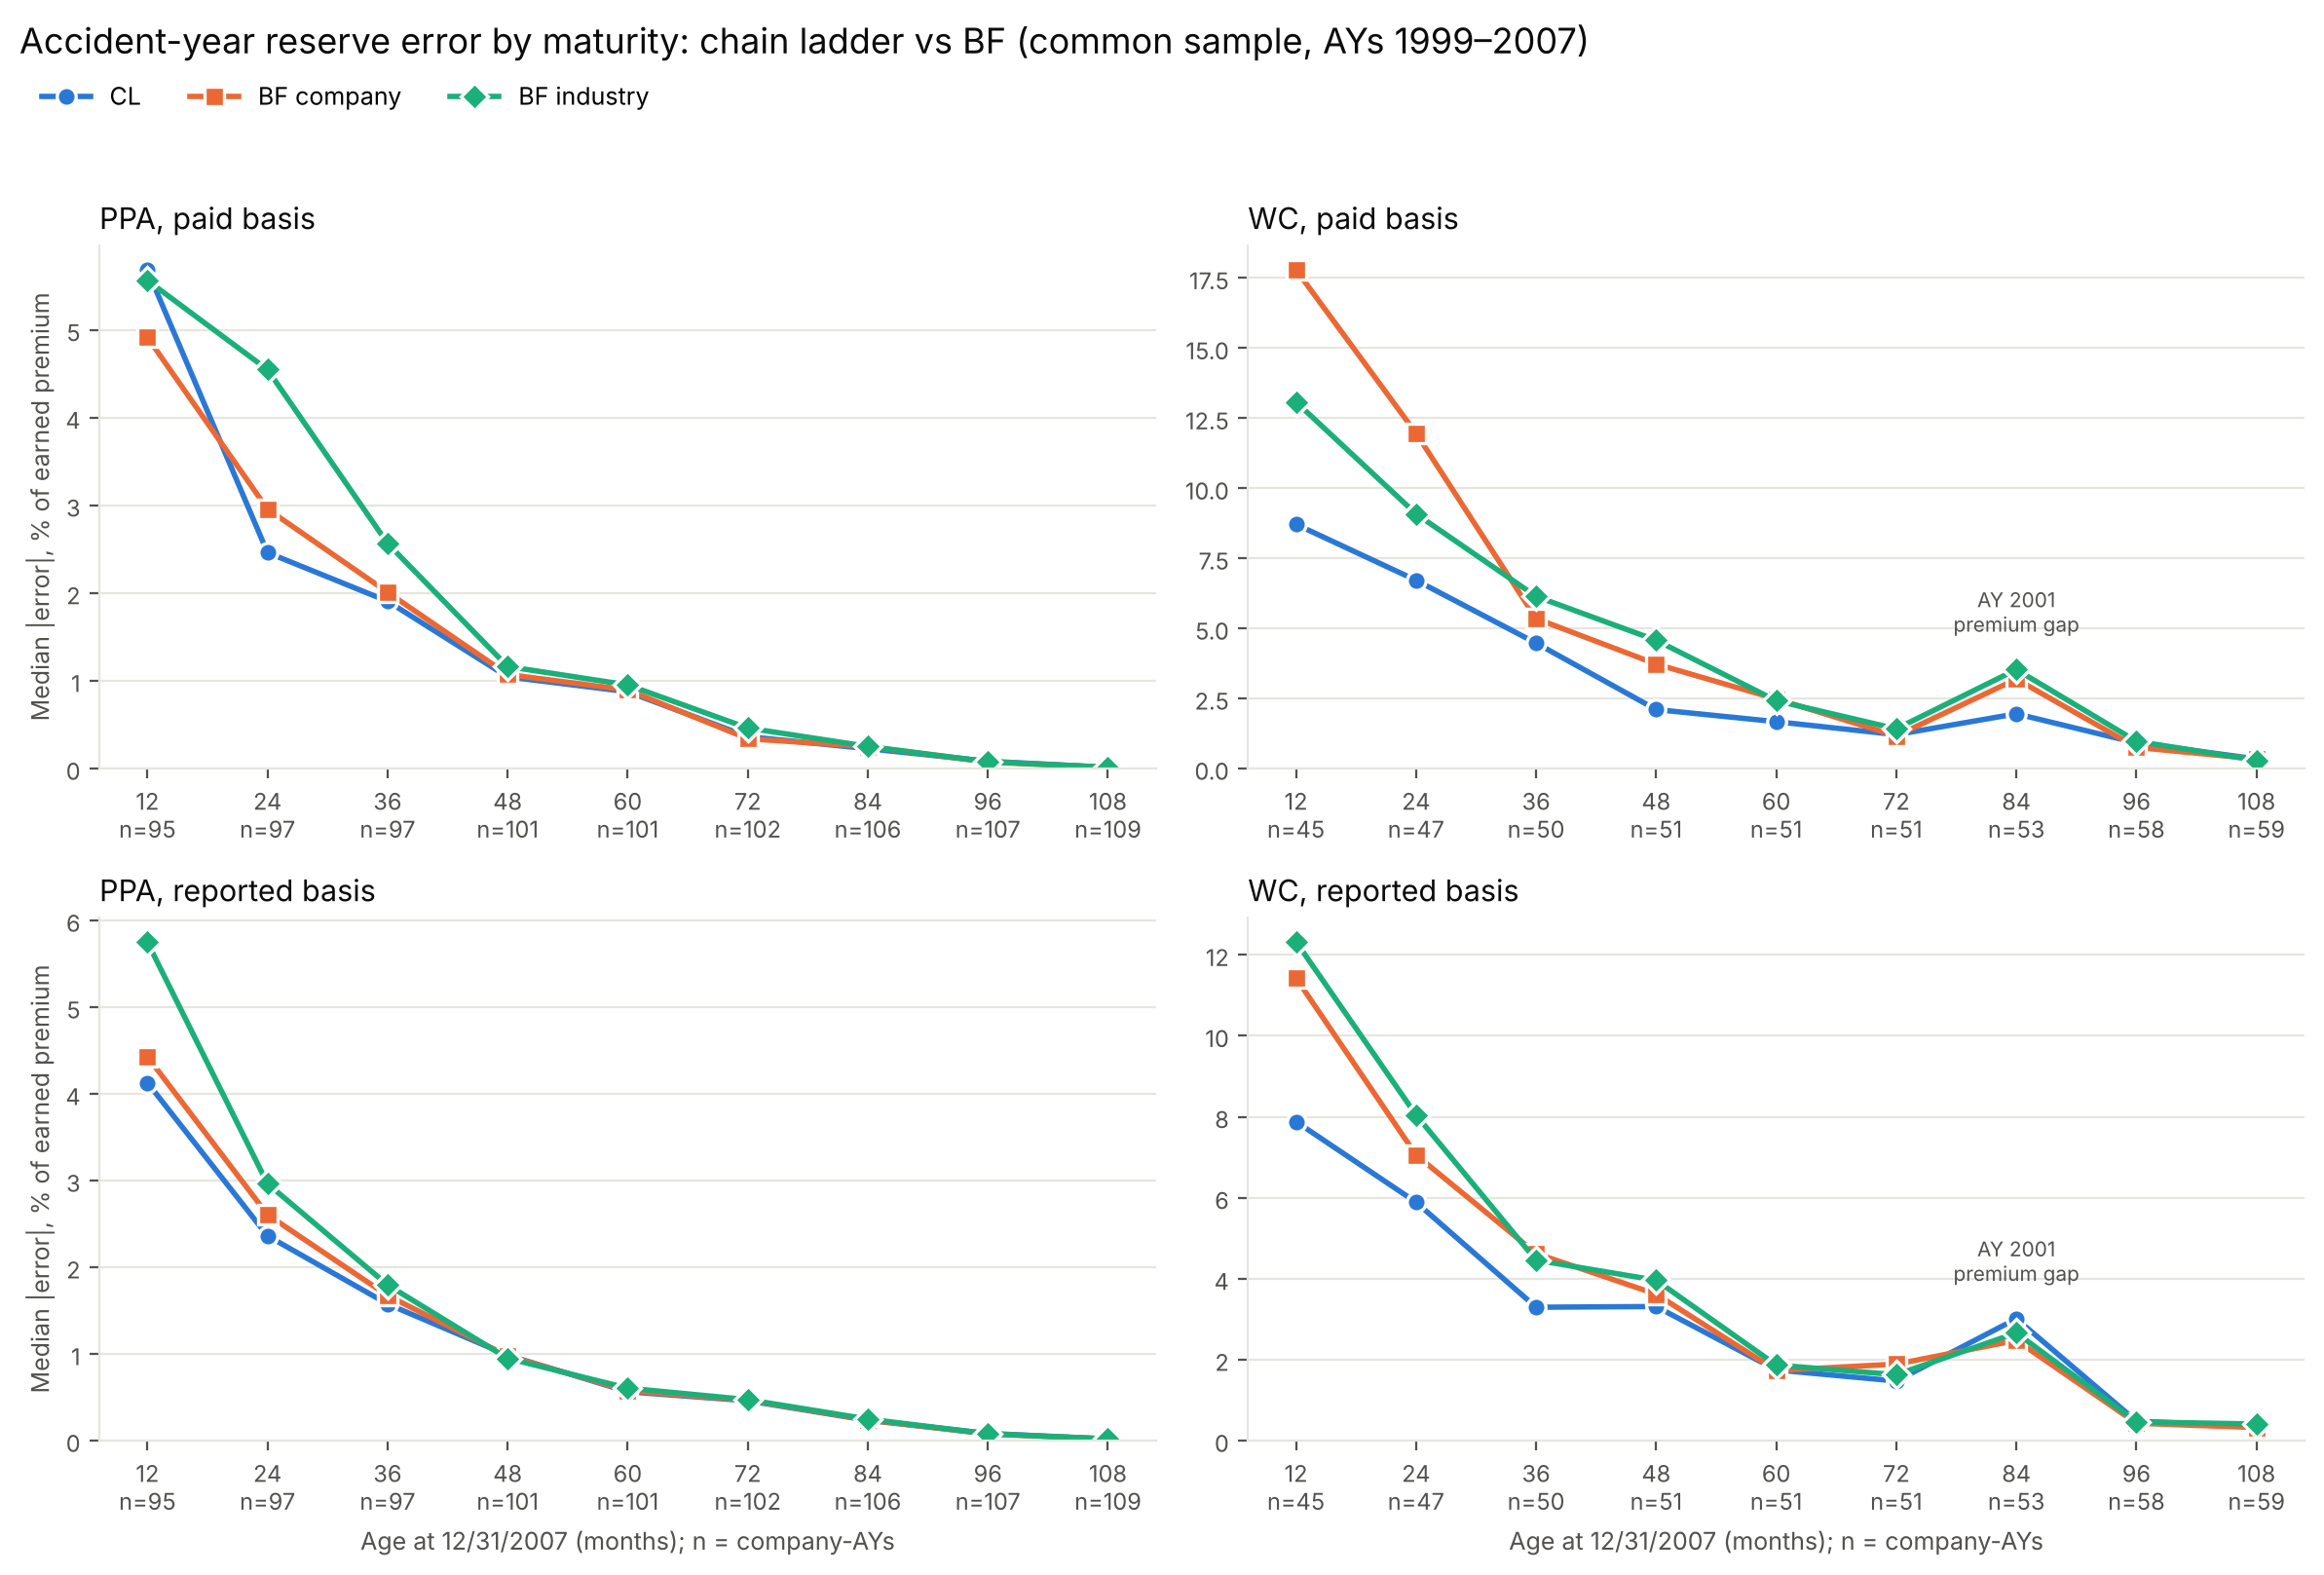

In [4]:
# Q2 chart: CL vs BF by maturity, one panel per line of business x basis. Expected claims is an
# order of magnitude worse at every age (table above), so it is left out to keep CL vs BF readable.
CHART = ["CL", "BF company", "BF industry"]
COLORS = dict(zip(CHART, ["#2a78d6", "#eb6834", "#1baf7a"]))  # validated slots 1-3, fixed order
MARKERS = dict(zip(CHART, ["o", "s", "D"]))  # secondary encoding: aqua is < 3:1 on white
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e6e5e0"

fig, axes = plt.subplots(2, 2, figsize=(12, 8.2), sharex="col")
for i, lob in enumerate(["PPA", "WC"]):
    for j, basis in enumerate(["paid", "reported"]):
        ax = axes[j, i]
        sub = q2[(q2.lob == lob) & (q2.basis == basis)]
        for c in CHART:
            s = sub[sub.combo == c].sort_values("age")
            ax.plot(s.age, s["median"] * 100, color=COLORS[c], lw=2, marker=MARKERS[c], ms=7,
                    markeredgecolor="white", markeredgewidth=1.2, label=c)
        n = sub.drop_duplicates("age").sort_values("age")
        ax.set_xticks(n.age)
        ax.set_xticklabels([f"{a}\nn={k}" for a, k in zip(n.age, n["size"])], fontsize=8)
        if lob == "WC":
            y84 = sub[(sub.age == 84) & sub.combo.isin(CHART)]["median"].max() * 100
            ax.annotate("AY 2001\npremium gap", (84, y84), xytext=(0, 14), textcoords="offset points",
                        ha="center", fontsize=7.5, color=MUTED)
        ax.set_title(f"{lob}, {basis} basis", loc="left", fontsize=11, color=INK)
        ax.set_ylim(bottom=0)
        ax.grid(axis="y", color=GRID, lw=0.8); ax.set_axisbelow(True)
        for sp in ["top", "right"]: ax.spines[sp].set_visible(False)
        for sp in ["left", "bottom"]: ax.spines[sp].set_color(GRID)
        ax.tick_params(colors=MUTED, labelsize=8.5)
        if i == 0: ax.set_ylabel("Median |error|, % of earned premium", color=MUTED, fontsize=9)
        if j == 1: ax.set_xlabel("Age at 12/31/2007 (months); n = company-AYs", color=MUTED, fontsize=9)
        ax.tick_params(axis="x", labelbottom=True)
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.suptitle("Accident-year reserve error by maturity: chain ladder vs BF (common sample, AYs 1999–2007)",
             x=0.01, ha="left", fontsize=13, color=INK)
fig.legend(handles, labels, loc="upper left", bbox_to_anchor=(0.01, 0.955), ncol=3, frameon=False, fontsize=9)
fig.tight_layout(rect=(0, 0, 1, 0.93))
fig.savefig(FIG / "q2_error_by_maturity.png", dpi=160, bbox_inches="tight")
plt.show()

### Data check: collapsed premium in WC AY 2001
The age-84 spike for WC (AY 2001) is a data issue, found here after grading. In 24 of 54 WC lines that have AY 2001, its net earned premium is under 25% of the line's median premium in the other AYs (as low as 0.7%) while its losses are normal; GRCODE 7080 has $2.5M of AY 2001 EP against $185M of losses at 120. Phase 1 found the same AY 2001 gap where premium was exactly 0 (rule 2 dropped those lines); these have small positive premium, so they passed. It is visible in known data (premium and paid losses at 12/31/2007), so a rule could have caught it before the freeze.

Effect: chain ladder doesn't use premium, so only its % of EP denominator is distorted; expected claims and BF use ELR × EP, so they understate these AYs. The pre-specified results stand as frozen. Below, a sensitivity: line totals recomputed without any company-AY whose premium is under 25% of the line's usual level (all AYs, both lines).

In [5]:
# Flag company-AYs with collapsed premium (known data: EP only) and recompute line totals without them
ep = ay.drop_duplicates(["lob", "GRCODE", "AccidentYear"])[["lob", "GRCODE", "AccidentYear", "ep"]]
ep98 = est[(est.AccidentYear == 1998)].drop_duplicates(["lob", "GRCODE"])[["lob", "GRCODE", "AccidentYear", "ep"]]
ep = pd.concat([ep, ep98])
flags = []
for lob, g in ep.groupby("lob"):
    p = g.pivot_table(index="GRCODE", columns="AccidentYear", values="ep")
    for y in p.columns:
        rel = p[y] / p.drop(columns=y).median(axis=1)
        flags.append(pd.DataFrame({"lob": lob, "GRCODE": rel.index, "AccidentYear": y, "rel_ep": rel.values}))
flags = pd.concat(flags).dropna()
flags["collapsed"] = flags.rel_ep < 0.25
print("Company-AYs with premium < 25% of the line's usual level:")
print(flags[flags.collapsed].groupby(["lob", "AccidentYear"]).size().unstack(fill_value=0))

aa = ay[ay.in_common & ay.headline].merge(flags[["lob", "GRCODE", "AccidentYear", "collapsed"]],
                                         on=["lob", "GRCODE", "AccidentYear"], how="left").fillna({"collapsed": False})
def line_med_abs(df):
    t = df.groupby(["lob", "basis", "combo", "GRCODE"]).agg(err=("error", "sum"), au=("actual_unpaid", "sum"))
    t = t[t.au > 0]
    return (t.err / t.au).abs().groupby(["lob", "basis", "combo"]).median()
sens = pd.DataFrame({"all AYs (frozen)": line_med_abs(aa), "collapsed AYs out": line_med_abs(aa[~aa.collapsed])})
print("\nMedian |error|, % of reserve, line totals, headline combinations:")
print(sens.to_string(float_format="{:.1%}".format))
sens.to_csv("../docs/phase4_premium_sensitivity.csv", float_format="%.6f")

Company-AYs with premium < 25% of the line's usual level:
AccidentYear  1998  1999  2000  2001  2002  2005  2006  2007
lob                                                         
PPA              6     5     4     4     2     2     3     5
WC               7     5     4    24     2     0     0     1

Median |error|, % of reserve, line totals, headline combinations:
                          all AYs (frozen)  collapsed AYs out
lob basis    combo                                           
PPA paid     BF company              22.8%              22.3%
             BF industry             22.3%              22.2%
             CL                      18.8%              18.2%
             EC company             103.4%             103.3%
             EC industry             95.7%              95.9%
    reported BF company              12.8%              12.6%
             BF industry             15.9%              15.9%
             CL                      14.7%              14.7%
           

## Question 5: BF sensitivity to the expected loss ratio
The plan's hypothesis: an ELR from the soft-market AY 1998 overstates hard-market AYs, biasing BF and expected claims but not chain ladder. Two checks:
1. **Industry loss ratio by AY.** The industry ELR is by definition the AY 1998 premium-weighted loss ratio at 120 months. The same ratio for every later AY (actual, at 120) shows how far each AY ended up from the ELR the methods used.
2. **Mechanism at the line level.** BF's unpaid estimate is ELR × EP × (1 − 1/CDF); its error splits into the ELR's miss on that AY times the unreported share, plus development noise. So BF error should track (ELR − actual AY loss ratio), and more strongly at young ages where 1 − 1/CDF is large. Spearman rank correlation per line of business, headline BF.
Then the paired company vs industry ELR comparison for BF.

In [6]:
# Q5.1: industry actual loss ratio at 120 by AY vs the ELR (= AY 1998 value)
act = ay.drop_duplicates(["lob", "GRCODE", "basis", "AccidentYear"])
lr = act.groupby(["lob", "basis", "AccidentYear"]).agg(loss=("actual_120", "sum"), ep=("ep", "sum"))
lr["lr"] = lr.loss / lr.ep
ay98 = est[(est.AccidentYear == 1998) & (est.method == "cl") & (est.average == HEAD)]
elr_ind = (ay98.groupby(["lob", "basis"]).latest.sum() / ay98.groupby(["lob", "basis"]).ep.sum()).rename("industry_elr")
q5 = lr.lr.unstack("AccidentYear").join(elr_ind)
print("Industry loss ratio at 120 by AY (AYs 1999-2007 actual; industry ELR = AY 1998).")
print("WC AY 2001 is inflated by the collapsed premium above.")
print((q5 * 100).round(1).to_string())
q5.to_csv("../docs/phase4_q5_loss_ratios.csv", float_format="%.6f")

Industry loss ratio at 120 by AY (AYs 1999-2007 actual; industry ELR = AY 1998).
WC AY 2001 is inflated by the collapsed premium above.
              1999  2000   2001  2002  2003  2004  2005  2006  2007  industry_elr
lob basis                                                                        
PPA paid      75.7  81.4   82.1  77.9  68.4  65.3  66.1  66.1  70.3          69.1
    reported  75.9  81.6   82.3  78.1  68.6  65.4  66.2  66.3  70.4          69.2
WC  paid      69.4  68.7   96.0  62.8  54.2  47.8  44.8  46.4  55.2          64.2
    reported  75.1  73.6  109.4  67.7  58.5  52.1  49.0  51.1  59.3          68.2


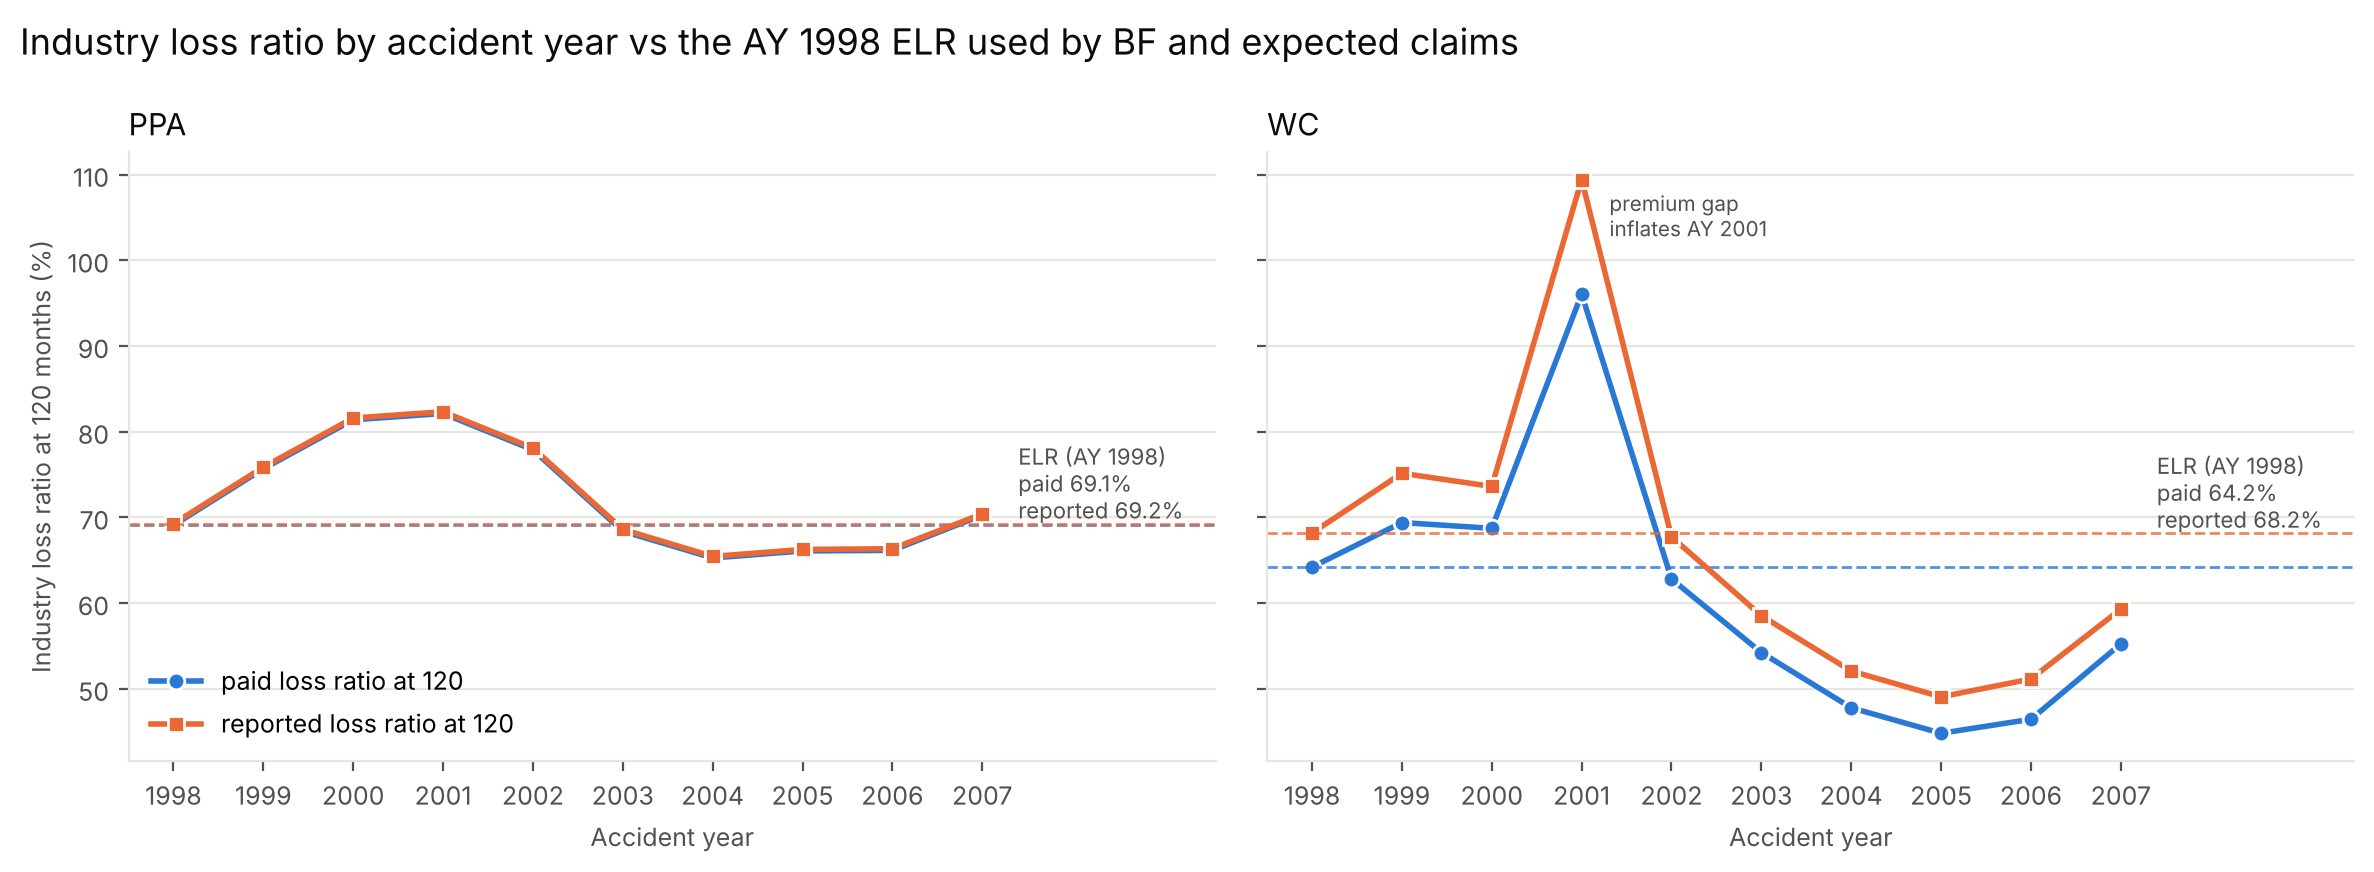

In [7]:
# Q5.1 chart: industry loss ratio by AY (AY 1998 = the industry ELR), ELR as a dashed reference
fig, axes = plt.subplots(1, 2, figsize=(12, 4.4), sharey=True)
BASIS_C = {"paid": "#2a78d6", "reported": "#eb6834"}
for ax, lob in zip(axes, ["PPA", "WC"]):
    for basis in ["paid", "reported"]:
        e = q5.loc[(lob, basis), "industry_elr"]
        s = pd.concat([pd.Series({1998: e}), lr.loc[(lob, basis)].lr]) * 100
        ax.plot(s.index, s.values, color=BASIS_C[basis], lw=2, marker="o" if basis == "paid" else "s",
                ms=6, markeredgecolor="white", label=f"{basis} loss ratio at 120")
        ax.axhline(e * 100, color=BASIS_C[basis], lw=1, ls="--", alpha=0.8)
    pe, re_ = q5.loc[(lob, "paid"), "industry_elr"], q5.loc[(lob, "reported"), "industry_elr"]
    ax.annotate(f"ELR (AY 1998)\npaid {pe:.1%}\nreported {re_:.1%}", (2007.4, max(pe, re_) * 100),
                va="bottom", fontsize=8, color=MUTED)
    if lob == "WC":
        ax.annotate("premium gap\ninflates AY 2001", (2001, lr.loc[(lob, "reported"), "lr"][2001] * 100),
                    xytext=(10, -4), textcoords="offset points", fontsize=7.5, color=MUTED, va="top")
    ax.set_title(lob, loc="left", fontsize=11, color=INK); ax.set_xticks(range(1998, 2008))
    ax.set_xlim(1997.5, 2009.6)
    ax.grid(axis="y", color=GRID, lw=0.8); ax.set_axisbelow(True)
    for sp in ["top", "right"]: ax.spines[sp].set_visible(False)
    for sp in ["left", "bottom"]: ax.spines[sp].set_color(GRID)
    ax.tick_params(colors=MUTED, labelsize=9); ax.set_xlabel("Accident year", color=MUTED, fontsize=9)
axes[0].set_ylabel("Industry loss ratio at 120 months (%)", color=MUTED, fontsize=9)
axes[0].legend(frameon=False, fontsize=9, loc="lower left")
fig.suptitle("Industry loss ratio by accident year vs the AY 1998 ELR used by BF and expected claims",
             x=0.01, ha="left", fontsize=13, color=INK)
fig.tight_layout(); fig.savefig(FIG / "q5_loss_ratio_by_ay.png", dpi=160, bbox_inches="tight"); plt.show()

In [8]:
# Q5.2: does BF error track the ELR's miss? AY level, headline BF, common sample
from scipy.stats import spearmanr
b = ay[ay.in_common & (ay.method == "bf") & (ay.average == HEAD) & ay.error.notna()].copy()
# ELR value per AY = EC estimate / EP (EC estimate = ELR x EP)
ec_est = pd.read_csv(R / "estimates.csv", usecols=["lob", "GRCODE", "basis", "AccidentYear", "method", "elr", "est"])
ec_est = ec_est[ec_est.method == "ec"].drop(columns="method")
b = b.merge(ec_est.rename(columns={"est": "ec_est"}), on=["lob", "GRCODE", "basis", "AccidentYear", "elr"])
b["elr_value"] = b.ec_est / b.ep
b["elr_miss"] = b.elr_value - b.actual_120 / b.ep
b["young"] = b.age <= 36
rows = []
for (lob, e, young), g in b.groupby(["lob", "elr", "young"]):
    r = spearmanr(g.elr_miss, g.pct_ep).statistic
    rows.append({"lob": lob, "elr": e, "ages": "12-36" if young else "48-108", "n": len(g),
                 "spearman": r, "med_elr_miss": g.elr_miss.median(), "med_bf_err_ep": g.pct_ep.median()})
q5b = pd.DataFrame(rows)
print(q5b.to_string(index=False, formatters={"spearman": "{:.2f}".format,
      "med_elr_miss": "{:+.1%}".format, "med_bf_err_ep": "{:+.1%}".format}))

lob      elr   ages    n spearman med_elr_miss med_bf_err_ep
PPA  company 48-108 1252     0.18        -3.7%         +0.0%
PPA  company  12-36  578     0.55        +3.0%         +1.1%
PPA industry 48-108 1252     0.19        -0.0%         +0.0%
PPA industry  12-36  578     0.50        +7.1%         +1.6%
 WC  company 48-108  646     0.38        -6.8%         +0.0%
 WC  company  12-36  284     0.79        +5.1%         +2.2%
 WC industry 48-108  646     0.42        +1.7%         +0.0%
 WC industry  12-36  284     0.59       +15.5%         +4.9%


In [9]:
# Q5.3: BF company vs industry ELR, paired on line totals (% of reserve), headline average
rows = []
for (lob, basis), g in w.groupby(level=[0, 1]):
    pair = g[["BF company", "BF industry"]].dropna()
    d = pair["BF company"].abs() - pair["BF industry"].abs()
    lo, hi = boot_median(d)
    rows.append({"lob": lob, "basis": basis, "n": len(d),
                 "med_signed_company": pair["BF company"].median(), "med_signed_industry": pair["BF industry"].median(),
                 "med_abs_company": pair["BF company"].abs().median(), "med_abs_industry": pair["BF industry"].abs().median(),
                 "med_diff": d.median(), "ci_lo": lo, "ci_hi": hi, "company_closer": (d < 0).mean()})
q5c = pd.DataFrame(rows)
print(q5c.to_string(index=False, formatters={c: "{:+.1%}".format for c in
      ["med_signed_company", "med_signed_industry", "med_diff", "ci_lo", "ci_hi"]} |
      {c: "{:.1%}".format for c in ["med_abs_company", "med_abs_industry", "company_closer"]}))

lob    basis   n med_signed_company med_signed_industry med_abs_company med_abs_industry med_diff ci_lo  ci_hi company_closer
PPA     paid 101              +7.8%              +14.8%           22.8%            22.3%    -1.8% -2.9%  +3.4%          52.5%
PPA reported 101              +4.5%               +3.9%           12.8%            15.9%    -0.0% -1.1%  +0.4%          50.5%
 WC     paid  56              +0.7%              +19.9%           41.9%            32.5%   +11.5% +5.9% +20.1%          32.1%
 WC reported  58              +2.7%              +11.7%           26.2%            29.6%    +1.4% -2.5%  +5.8%          46.6%


## Question 3: paid vs reported basis, PPA vs WC (short table)
Headline chain ladder and BF (company ELR), common sample, line totals. Reported-basis unpaid includes case still open at 120, so part of any paid vs reported gap is that built-in difference, not estimation error (`docs/phase3_open_case_by_line.csv`).

In [10]:
q3 = (h[h.combo.isin(["CL", "BF company"])].groupby(["lob", "combo", "basis"]).pct_reserve
        .agg(n="count", median="median", med_abs=lambda s: s.abs().median()).unstack("basis"))
print(q3.to_string(formatters={c: "{:+.1%}".format for c in q3.columns if c[0] == "median"} |
                               {c: "{:.1%}".format for c in q3.columns if c[0] == "med_abs"}))
oc = pd.read_csv("../docs/phase3_open_case_by_line.csv")
print("\nOpen case at 120, median share of actual reported unpaid:",
      oc.groupby("lob").pct_of_reported_unpaid.median().map("{:.1%}".format).to_dict())

                  n          median          med_abs         
basis          paid reported   paid reported    paid reported
lob combo                                                    
PPA BF company  101      101  +7.8%    +4.5%   22.8%    12.8%
    CL          101      101  +6.9%    +3.2%   18.8%    14.7%
WC  BF company   56       58  +0.7%    +2.7%   41.9%    26.2%
    CL           56       58  +4.5%    +5.0%   28.5%    27.8%

Open case at 120, median share of actual reported unpaid: {'PPA': '0.5%', 'WC': '15.1%'}


## Question 4: best averaging method (short table)
Chain ladder under each of the 6 averages, common sample, median |error| as % of reserve on line totals, ranked within each line of business × basis. **In-sample:** the averages are scored on the same data used to rank them, so the winner's edge is likely overstated; only the headline (volume-weighted all years) was picked in advance (D3). An out-of-sample check needs the second era (plan extension).

In [11]:
cl = lines[lines.in_common & (lines.method == "cl")]
q4 = cl.groupby(["lob", "basis", "average"]).pct_reserve.agg(
    med_abs=lambda s: s.abs().median(), median="median", n="count").reset_index()
q4["rank"] = q4.groupby(["lob", "basis"]).med_abs.rank().astype(int)
print(q4.sort_values(["lob", "basis", "rank"]).to_string(index=False,
      formatters={"med_abs": "{:.1%}".format, "median": "{:+.1%}".format}))

lob    basis    average med_abs median   n  rank
PPA     paid   simple_3   15.4%  +3.6% 101     1
PPA     paid   volume_3   16.0%  +3.9% 101     2
PPA     paid   volume_5   16.8%  +4.9% 101     3
PPA     paid   simple_5   17.1%  +6.1% 101     4
PPA     paid volume_all   18.8%  +6.9% 101     5
PPA     paid simple_all   20.4%  +8.1% 101     6
PPA reported   simple_3    8.8%  +0.2% 101     1
PPA reported   volume_3    9.9%  +0.1% 101     2
PPA reported   volume_5   12.6%  +0.2% 101     3
PPA reported   simple_5   12.7%  +1.1% 101     4
PPA reported volume_all   14.7%  +3.2% 101     5
PPA reported simple_all   15.0%  +4.6% 101     6
 WC     paid   volume_5   25.0%  +0.5%  56     1
 WC     paid   volume_3   27.2%  -2.5%  56     2
 WC     paid volume_all   28.5%  +4.5%  56     3
 WC     paid   simple_5   29.0%  -0.3%  56     4
 WC     paid   simple_3   29.3%  -3.8%  56     5
 WC     paid simple_all   29.5%  +2.9%  56     6
 WC reported   volume_3   26.7%  +6.6%  58     1
 WC reported   simpl

## Error drivers
**Ceded swing (reinsurance change, probe 7).** A line whose ceded share of premium moved by more than 0.5 across AYs may have changed reinsurance. Excess of loss speeds up net development, so chain ladder on older factors would overstate; quota share changes nothing. Schedule P doesn't record the type, so this is a confounder, not a cause: the split below shows whether high-swing lines have larger chain ladder errors, not why.

In [12]:
s = h[h.combo == "CL"].assign(high_swing=lambda d: d.ceded_swing > 0.5)
drv = s.groupby(["lob", "basis", "high_swing"]).pct_reserve.agg(
    n="count", median="median", med_abs=lambda x: x.abs().median())
print(drv.to_string(formatters={"median": "{:+.1%}".format, "med_abs": "{:.1%}".format}))

                          n median med_abs
lob basis    high_swing                   
PPA paid     False       86  +6.7%   16.7%
             True        15  +6.9%   30.5%
    reported False       86  +2.7%   14.8%
             True        15  +5.7%   13.6%
WC  paid     False       35 +13.7%   29.7%
             True        21  -8.3%   19.4%
    reported False       37 +12.3%   28.4%
             True        21  -9.0%   24.4%


**Survivorship (direction, not size).** Results cover company-lines that filed through at least 2007 and passed cleaning. Companies that exit or fail are more likely to have unstable development and weak reserving, so the retained sample leans stable and measured errors are likely a lower bound for all methods. Chain ladder relies on each company's own history most, so it likely benefits most from the stable sample; the gap between chain ladder and BF may be overstated. Incomplete lines (rule 6) keep some companies that stopped filing for the AYs they have, which narrows but doesn't remove the bias.